# 03 — Missing Values and Numerical Scaling

[Previous](./02_Baselines_and_Validation.ipynb) | [Repository guide](../README.md) | [Next](./04_Categorical_Encoding.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** compare simple missing-value treatments and numerical scalers without changing the model or validation folds.

The EDA found only 1–3.2% missingness in six columns, so extra complexity must earn a measurable F1 improvement. `solution.csv` is never read.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


In [1]:
import warnings

# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_backend

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42
# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)
print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")
print("solution.csv: intentionally not loaded")

Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
solution.csv: intentionally not loaded


## 1. Measure the problem

`train.isna().sum()` counts missing cells in each column. `isna()` returns `True` where a value is absent; summing `True` values gives the count.

**Imputation** replaces missing cells so the model can use the row. A **missing indicator** is an added `0/1` column that remembers which value was absent.


,missing_rows,missing_%
minute_taken,202,1.0100
stadium_capacity,547,2.7350
temperature,581,2.9050
referee_strictness,581,2.9050
weather_humidity,622,3.1100
jersey_color,639,3.1950


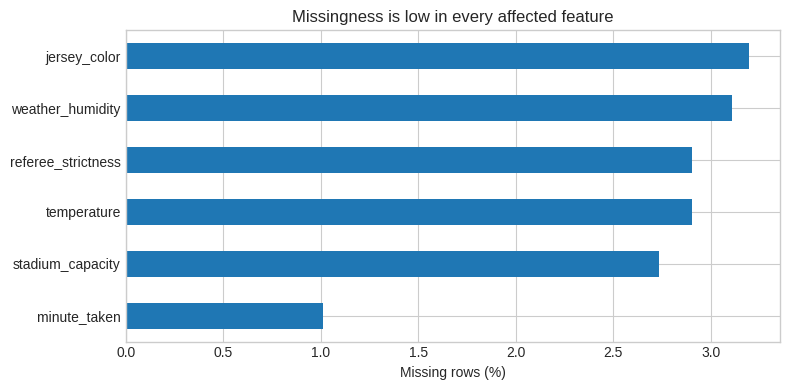

In [4]:
missing = pd.DataFrame({
    "missing_rows": train.isna().sum(),
    "missing_%": train.isna().mean().mul(100),
}).query("missing_rows > 0").sort_values("missing_%")
display(missing)
ax = missing["missing_%"].plot.barh(figsize=(8, 4), title="Missingness is low in every affected feature")
ax.set(xlabel="Missing rows (%)", ylabel="")
plt.tight_layout()
plt.show()

### What about `dropna()`?

- `train.dropna()` removes every training row containing a missing value.
- `train.dropna(axis=1)` removes every affected column.
- Dropping can be reasonable when only a tiny, random fraction is lost or a column is almost entirely missing.

Here it would discard usable penalty events or whole features. We also cannot drop test rows because Kaggle expects one prediction for every test `id`, so we compare imputation instead.


In [5]:
complete_rows = train.dropna()
affected_columns = train.columns[train.isna().any()].tolist()
print(f"Rows before dropna(): {len(train):,}")
print(f"Rows after train.dropna(): {len(complete_rows):,} ({len(train) - len(complete_rows):,} removed)")
print(f"Columns removed by dropna(axis=1): {affected_columns}")

numeric_missing_columns = [column for column in missing.index if pd.api.types.is_numeric_dtype(train[column])]
example_column = numeric_missing_columns[-1]
example_rows = train.loc[train[example_column].isna(), ["id", example_column]].head(5).copy()
example_rows[f"{example_column}_median_imputed"] = train[example_column].median()
display(example_rows)


Rows before dropna(): 20,000
Rows after train.dropna(): 17,033 (2,967 removed)
Columns removed by dropna(axis=1): ['jersey_color', 'referee_strictness', 'stadium_capacity', 'temperature', 'weather_humidity', 'minute_taken']


,id,weather_humidity,weather_humidity_median_imputed
13,13,NaN,59.0000
27,27,NaN,59.0000
28,28,NaN,59.0000
95,95,NaN,59.0000
108,108,NaN,59.0000


## 2. Imputation methods in beginner language

| Method | Simple meaning | Main trade-off |
|---|---|---|
| Median + mode | Numbers get the middle observed value; text gets the most common label | Stable and easy; treats missing as typical |
| Mean + mode | Numbers get the arithmetic average | Familiar; extreme values can pull the mean |
| Median + indicators | Fill as above and add `was_missing = 1` | Lets the model learn whether missingness matters |
| Constant + indicators | Fill with a clearly artificial value and add a flag | Preserves “unknown,” but the constant can distort distance |

Example: if `minute_taken` is missing and the training-fold median is `54`, the model receives `54`; with an indicator it also receives `minute_taken_was_missing = 1`.

All fill values are learned from the training part of each fold. Using the validation fold to calculate a median would be leakage.


In [6]:
FEATURES = [column for column in train.columns if column not in [TARGET] + ID_COLUMNS]
NUMERICAL = train[FEATURES].select_dtypes(include=np.number).columns.tolist()
CATEGORICAL = [column for column in FEATURES if column not in NUMERICAL]
X, y = train[FEATURES], train[TARGET].astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def build_pipeline(numeric_imputer, categorical_imputer, scaler):
    numeric_steps = [("imputer", clone(numeric_imputer))]
    if scaler is not None:
        numeric_steps.append(("scaler", clone(scaler)))
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), NUMERICAL),
        ("categorical", Pipeline([
            ("imputer", clone(categorical_imputer)),
            ("one_hot", OneHotEncoder(handle_unknown="ignore")),
        ]), CATEGORICAL),
    ])
    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)),
    ])

def evaluate(name, pipeline, phase):
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        with parallel_backend("threading"):
            probabilities = cross_val_predict(pipeline, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    converged = not any(issubclass(item.category, ConvergenceWarning) for item in caught_warnings)
    predictions = (probabilities >= 0.50).astype(int)
    fold_f1 = [f1_score(y.iloc[index], predictions[index]) for _, index in cv.split(X, y)]
    return {
        "phase": phase, "method": name, "converged": converged,
        "f1": f1_score(y, predictions), "f1_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions), "recall": recall_score(y, predictions),
        "accuracy": accuracy_score(y, predictions), "roc_auc": roc_auc_score(y, probabilities),
    }

In [7]:
experiments = []
imputation_specs = [
    ("Median + mode", SimpleImputer(strategy="median"), SimpleImputer(strategy="most_frequent")),
    ("Mean + mode", SimpleImputer(strategy="mean"), SimpleImputer(strategy="most_frequent")),
    ("Median + indicators", SimpleImputer(strategy="median", add_indicator=True), SimpleImputer(strategy="constant", fill_value="__MISSING__")),
    ("Constant + indicators", SimpleImputer(strategy="constant", fill_value=-999, add_indicator=True), SimpleImputer(strategy="constant", fill_value="__MISSING__")),
]
for name, numeric_imputer, categorical_imputer in imputation_specs:
    pipeline = build_pipeline(numeric_imputer, categorical_imputer, StandardScaler())
    experiments.append(evaluate(name, pipeline, "imputation"))

imputation_results = pd.DataFrame(experiments).sort_values("f1", ascending=False)
display(imputation_results)

,phase,method,converged,f1,f1_std,precision,recall,accuracy,roc_auc
2,imputation,Median + indicators,True,0.8483,0.0055,0.8527,0.8439,0.8641,0.9402
0,imputation,Median + mode,True,0.8482,0.0054,0.8530,0.8435,0.8641,0.9404
1,imputation,Mean + mode,True,0.8482,0.0054,0.8530,0.8435,0.8641,0.9404
3,imputation,Constant + indicators,True,0.8478,0.0052,0.8522,0.8435,0.8637,0.9402


## 3. Do we need standardization and log “normalization”?

They solve different problems:

- **Standardization:** subtracts the training mean and divides by the training standard deviation. It gives logistic regression comparable units and improves optimization.
- **Min–Max scaling:** maps the training range near `0–1`; this is sometimes called normalization.
- **Robust scaling:** uses the median and IQR, so extremes matter less.
- **Log transformation:** compresses large magnitudes and can reduce strong right skew. It does not standardize units and does not guarantee a normal distribution.

`current_score_diff` contains negative values, so ordinary `log(x)` is invalid. We test a **signed log** (`sign(x) × log(1+|x|)`) followed by StandardScaler. Tree models usually need neither standardization nor log scaling.


In [8]:
def signed_log1p(values):
    return np.sign(values) * np.log1p(np.abs(values))


scaling_specs = [
    ("StandardScaler", StandardScaler()),
    ("RobustScaler", RobustScaler()),
    ("MinMaxScaler", MinMaxScaler()),
    ("Signed log + StandardScaler", Pipeline([
        ("signed_log", FunctionTransformer(signed_log1p, validate=False)),
        ("standard", StandardScaler()),
    ])),
]
for name, scaler in scaling_specs:
    if name == "StandardScaler":
        continue  # Median + mode with StandardScaler was already evaluated above.
    pipeline = build_pipeline(
        SimpleImputer(strategy="median"),
        SimpleImputer(strategy="most_frequent"),
        scaler,
    )
    experiments.append(evaluate(name, pipeline, "scaling"))

standard_row = next(row.copy() for row in experiments if row["method"] == "Median + mode")
standard_row.update({"phase": "scaling", "method": "StandardScaler"})
experiments.append(standard_row)
experiments.append({
    "phase": "scaling", "method": "No scaling", "converged": False,
    "f1": np.nan, "f1_std": np.nan, "precision": np.nan,
    "recall": np.nan, "accuracy": np.nan, "roc_auc": np.nan,
})
results = pd.DataFrame(experiments).sort_values(["phase", "f1"], ascending=[True, False])
display(results)


,phase,method,converged,f1,f1_std,precision,recall,accuracy,roc_auc
2,imputation,Median + indicators,True,0.8483,0.0055,0.8527,0.8439,0.8641,0.9402
0,imputation,Median + mode,True,0.8482,0.0054,0.8530,0.8435,0.8641,0.9404
1,imputation,Mean + mode,True,0.8482,0.0054,0.8530,0.8435,0.8641,0.9404
3,imputation,Constant + indicators,True,0.8478,0.0052,0.8522,0.8435,0.8637,0.9402
5,scaling,MinMaxScaler,True,0.8492,0.0053,0.8538,0.8447,0.8650,0.9403
4,scaling,RobustScaler,True,0.8484,0.0054,0.8528,0.8440,0.8642,0.9404
7,scaling,StandardScaler,True,0.8482,0.0054,0.8530,0.8435,0.8641,0.9404
6,scaling,Signed log + StandardScaler,True,0.8142,0.0050,0.8233,0.8054,0.8346,0.9161
8,scaling,No scaling,False,NaN,NaN,NaN,NaN,NaN,NaN


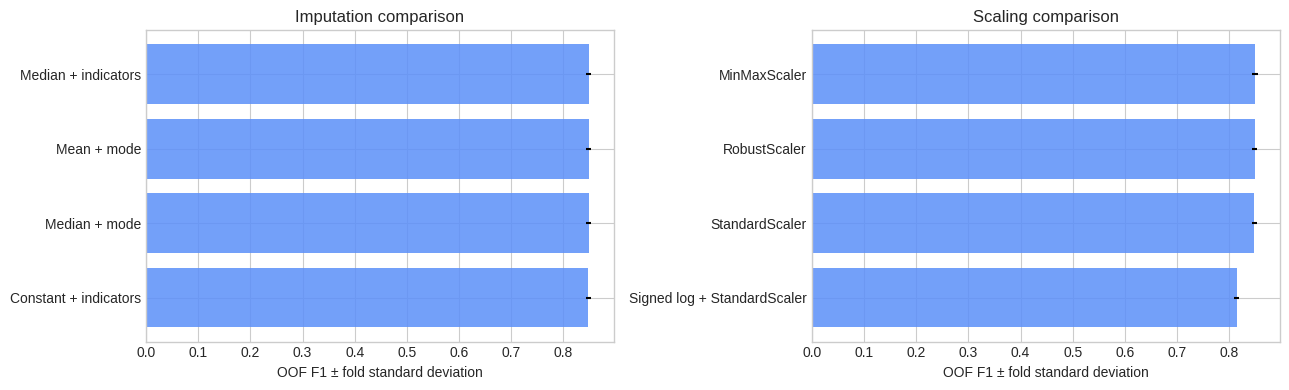

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for ax, phase in zip(axes, ["imputation", "scaling"]):
    subset = results.query("phase == @phase").dropna(subset=["f1"]).sort_values("f1")
    ax.barh(subset["method"], subset["f1"], xerr=subset["f1_std"], color="#5b8ff9", alpha=.85)
    ax.set(title=f"{phase.title()} comparison", xlabel="OOF F1 ± fold standard deviation")
plt.tight_layout()
plt.show()

### Concrete dataset example: one value under each transformation

The raw unit changes, but the row’s meaning and order are preserved. The fitted pipeline uses training-fold statistics; the table below is only an intuitive full-train illustration.


In [10]:
example_feature = "stadium_capacity"
example_values = train[example_feature].dropna().quantile([0.1, 0.5, 0.9]).to_numpy()
example_table = pd.DataFrame({"raw": example_values})
example_table["standardized"] = (example_values - train[example_feature].mean()) / train[example_feature].std()
example_table["min_max"] = (example_values - train[example_feature].min()) / (train[example_feature].max() - train[example_feature].min())
example_table["signed_log"] = signed_log1p(example_values)
display(example_table)


,raw,standardized,min_max,signed_log
0,19698.2000,-1.3404,0.0693,9.8883
1,56315.0000,-0.0235,0.3312,10.9387
2,92935.6000,1.2936,0.5931,11.4397


## 4. Decision

`f1_std` is the fold-to-fold standard deviation. If two F1 scores differ by less than ordinary fold variation, prefer the simpler method and recheck close choices with more seeds.

In [11]:
best_imputer = results.query("phase == 'imputation'").sort_values("f1", ascending=False).iloc[0]
best_scaler = results.query("phase == 'scaling'").sort_values("f1", ascending=False).iloc[0]
simple = results.query("phase == 'imputation' and method == 'Median + mode'").iloc[0]
standard = results.query("phase == 'scaling' and method == 'StandardScaler'").iloc[0]
unscaled = results.query("phase == 'scaling' and method == 'No scaling'").iloc[0]
print(f"Best imputation: {best_imputer['method']} | F1 {best_imputer['f1']:.4f}")
print(f"Best scaler: {best_scaler['method']} | F1 {best_scaler['f1']:.4f}")
if best_imputer['f1'] - simple['f1'] < simple['f1_std']:
    print("Imputation decision: no clear gain beyond fold variation; keep median + mode.")
else:
    print("Imputation decision: the best alternative deserves a repeated-CV check.")
if best_scaler['f1'] - standard['f1'] < standard['f1_std']:
    print("Scaling decision: the gain is smaller than fold variation; keep StandardScaler.")
else:
    print("Scaling decision: the best scaler deserves a repeated-CV check.")
if not unscaled['converged']:
    print("No-scaling note: optimization did not converge, so its exact score is not reliable.")

Best imputation: Median + indicators | F1 0.8483
Best scaler: MinMaxScaler | F1 0.8492
Imputation decision: no clear gain beyond fold variation; keep median + mode.
Scaling decision: the gain is smaller than fold variation; keep StandardScaler.
No-scaling note: optimization did not converge, so its exact score is not reliable.


## Other alternatives

- **KNN imputation:** fills from similar rows; can be slow and depends on meaningful distances.
- **Iterative imputation:** predicts each incomplete feature from the others; more flexible but slower and easier to overcomplicate.
- **MICE:** repeats model-based imputation to represent uncertainty; mainly useful for statistical inference.
- **Group-based imputation:** fills within real repeated groups; the supplied IDs are unique, so it is not justified here.
- **Native missing handling:** boosting trees such as CatBoost can learn how to route missing values directly.
- **Drop rows or columns:** simple, but discards information and may introduce bias.

These are explained but not run because missingness is low and the simpler comparison answers the immediate dataset question.

In [12]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)
output_path = results_dir / "03_missing_values_and_scaling.csv"
results.to_csv(output_path, index=False)
print(f"Saved: {output_path}")

Saved: /kaggle/working/03_missing_values_and_scaling.csv


## Why this preprocessing decision is justified

**Technical evidence:** missingness is only about 1–3%, simple imputers perform within ordinary fold variation, and unscaled logistic regression does not converge reliably. The signed-log candidate is kept only if validation gives a stable gain.

**Theoretical reason:** median/mode imputation makes every required prediction possible with minimal assumptions, while StandardScaler puts numerical coefficients on comparable units. Log transformation is optional because it addresses skew—not missingness or unequal units.
